# Linear Algebra for Deep Learning

Based on Ian Goodfellow's *Deep Learning*, Chapter 2.

Run each cell in order (Shift + Enter).


## Setup

In [1]:
import numpy as np
import matplotlib.pyplot as plt

np.set_printoptions(precision=3, suppress=True)
plt.rcParams['figure.figsize'] = (8, 6)
plt.rcParams['axes.grid'] = True
print("Setup complete.")


Setup complete.


## 1. Scalars

A scalar is a single number. In deep learning it could be a learning rate, a loss, or a weight.

In [2]:
a = 3
b = -1.5
c = np.pi
print(a, b, c)

s = np.array(5.0)
print("ndim:", s.ndim)   # 0 -> scalar


3 -1.5 3.141592653589793
ndim: 0


## 2. Vectors

A vector is an ordered list of numbers: $\mathbf{x} \in \mathbb{R}^n$.

x = [3. 4. 0.]
shape: (3,)
ndim : 1


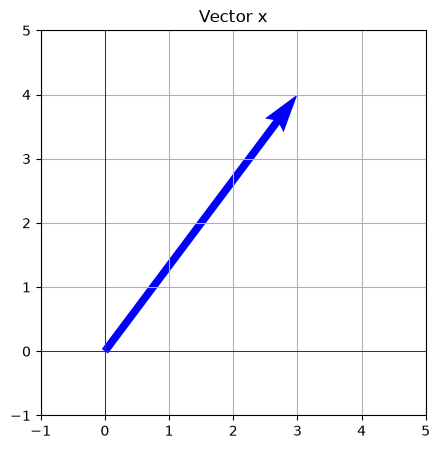

In [ ]:
x = np.array([3.0, 4.0, 0.0]) #horizontal row of numbers
print("x =", x)
print("shape:", x.shape)
print("ndim :", x.ndim) #.ndim gives us the number of dimensions. this is 1-dimensional

fig, ax = plt.subplots(figsize=(5,5))
ax.quiver(0, 0, x[0], x[1], angles='xy', scale_units='xy', scale=1,
          color='blue', width=0.02)
ax.set_xlim(-1, 5); ax.set_ylim(-1, 5)
ax.set_aspect('equal')
ax.axhline(0, color='black', lw=0.5)
ax.axvline(0, color='black', lw=0.5)
ax.set_title("Vector x")
plt.show()


## 3. Tensors

A tensor is an N-dimensional array. Essentially the general case.

In [ ]:
print("scalar :", np.array(5).shape) #shape gives you
print("vector :", np.array([1,2,3]).shape)
print("matrix :", np.array([[1,2],[3,4],[5,6]]).shape)
print("3-D    :", np.zeros((2,3,4)).shape)
print("4-D    :", np.zeros((16,32,32,3)).shape)   # batch of RGB images


scalar : ()
vector : (3,)
matrix : (3, 2)
3-D    : (2, 3, 4)
4-D    : (16, 32, 32, 3)


## 4. Transpose

$(A^T)_{i,j} = A_{j,i}$

In [5]:
A = np.array([[1,2,3],[4,5,6]])
print("A:\n", A)
print("A.T:\n", A.T)
print("Check:", A.T[0,1] == A[1,0])


A:
 [[1 2 3]
 [4 5 6]]
A.T:
 [[1 4]
 [2 5]
 [3 6]]
Check: True


## 5. Matrix (Dot) Product

$C = AB$,  $C_{i,j} = \sum_k A_{i,k} B_{k,j}$.

Shape rule: $(m \times n) \cdot (n \times p) = (m \times p)$.

In [6]:
A = np.array([[1,2],[3,4],[5,6]])    # 3x2
B = np.array([[7,8,9],[10,11,12]])   # 2x3

C = A @ B
print("C shape:", C.shape)
print("C:\n", C)

manual = sum(A[0,k]*B[k,0] for k in range(A.shape[1]))
print("Manual C[0,0]:", manual, " NumPy:", C[0,0])


C shape: (3, 3)
C:
 [[ 27  30  33]
 [ 61  68  75]
 [ 95 106 117]]
Manual C[0,0]: 27  NumPy: 27


### 5.1 Matrix as a transformation

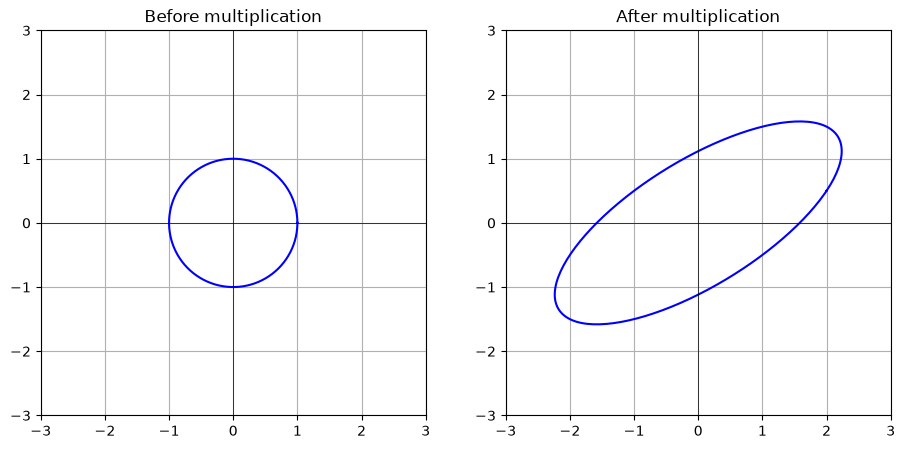

In [7]:
theta = np.linspace(0, 2*np.pi, 200)
circle = np.stack([np.cos(theta), np.sin(theta)])

A = np.array([[2.0, 1.0],[0.5, 1.5]])
transformed = A @ circle

fig, axes = plt.subplots(1, 2, figsize=(11,5))
for ax, data, title in [(axes[0], circle,      "Before multiplication"),
                        (axes[1], transformed, "After multiplication")]:
    ax.plot(data[0], data[1], 'b-')
    ax.axhline(0, color='black', lw=0.5)
    ax.axvline(0, color='black', lw=0.5)
    ax.set_aspect('equal')
    ax.set_xlim(-3,3); ax.set_ylim(-3,3)
    ax.set_title(title)
plt.show()


## 6. Identity Matrix

$I_n x = x$.

In [8]:
I3 = np.eye(3)
print(I3)

x = np.array([5.0, -2.0, 7.0])
print("I3 @ x =", I3 @ x)
print("Equal to x?", np.allclose(I3 @ x, x))


[[1. 0. 0.]
 [0. 1. 0.]
 [0. 0. 1.]]
I3 @ x = [ 5. -2.  7.]
Equal to x? True


## 7. Systems of Equations: $Ax = b$

In [9]:
A = np.array([[2., 3.],[4., -1.]])
b = np.array([7., 1.])
x = np.linalg.solve(A, b)
print("x =", x)
print("A @ x =", A @ x)


x = [0.714 1.857]
A @ x = [7. 1.]


## 8. No / many / one solution

In [10]:
cases = [
    ("No solution",    np.array([[1.,1.],[1.,1.]]), np.array([1.,2.])),
    ("Many solutions", np.array([[1.,1.],[2.,2.]]), np.array([1.,2.])),
    ("Exactly one",    np.array([[2.,3.],[4.,-1.]]), np.array([7.,1.])),
]
for name, A_, b_ in cases:
    print(f"--- {name} --- det = {np.linalg.det(A_):.4f}")
    try:
        print("   x =", np.linalg.solve(A_, b_))
    except np.linalg.LinAlgError as e:
        print("   ", e)


--- No solution --- det = 0.0000
    Singular matrix
--- Many solutions --- det = 0.0000
    Singular matrix
--- Exactly one --- det = -14.0000
   x = [0.714 1.857]


## 9. Matrix Inversion

$A^{-1}A = I$. Numerically unstable, but useful for abstract reasoning.

In [11]:
A = np.array([[2., 3.],[4., -1.]])
A_inv = np.linalg.inv(A)
print("A_inv:\n", A_inv)
print("A @ A_inv:\n", A @ A_inv)

b = np.array([7., 1.])
print("x = A_inv @ b =", A_inv @ b)


A_inv:
 [[ 0.071  0.214]
 [ 0.286 -0.143]]
A @ A_inv:
 [[1. 0.]
 [0. 1.]]
x = A_inv @ b = [0.714 1.857]


## 10. Non-invertible (singular) matrix

In [12]:
A_sing = np.array([[1., 2.],[2., 4.]])   # row 2 = 2 * row 1
print("det :", np.linalg.det(A_sing))
print("rank:", np.linalg.matrix_rank(A_sing))

try:
    np.linalg.inv(A_sing)
except np.linalg.LinAlgError as e:
    print("Cannot invert:", e)


det : 0.0
rank: 1
Cannot invert: Singular matrix


## 11. Norms

$\|x\|_p = \left(\sum_i |x_i|^p\right)^{1/p}$

In [13]:
x = np.array([3., -4., 1.])
print("L1  :", np.linalg.norm(x, 1))
print("L2  :", np.linalg.norm(x, 2))
print("Linf:", np.linalg.norm(x, np.inf))


L1  : 8.0
L2  : 5.0990195135927845
Linf: 4.0


### Unit balls for L1, L2, Linf

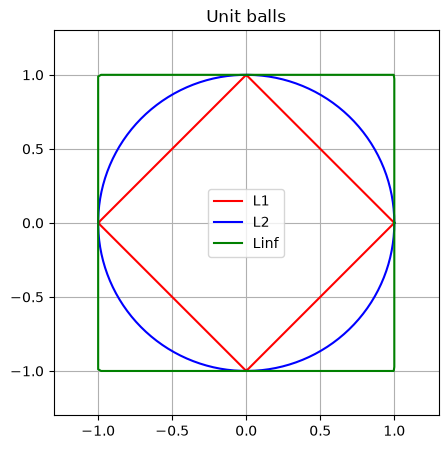

In [14]:
angles = np.linspace(0, 2*np.pi, 400)
vecs = np.stack([np.cos(angles), np.sin(angles)])

fig, ax = plt.subplots(figsize=(5,5))
for p, c, label in [(1,'red','L1'), (2,'blue','L2'), (np.inf,'green','Linf')]:
    n = np.linalg.norm(vecs, p, axis=0)
    unit = vecs / n
    ax.plot(unit[0], unit[1], color=c, label=label)
ax.set_aspect('equal')
ax.set_xlim(-1.3,1.3); ax.set_ylim(-1.3,1.3)
ax.legend()
ax.set_title("Unit balls")
plt.show()


## 12. Special Matrices

In [15]:
# Unit vector
v = np.array([3., 4.])
v_unit = v / np.linalg.norm(v)
print("unit vector:", v_unit, "norm:", np.linalg.norm(v_unit))

# Symmetric
S = np.array([[1., 2.],[2., 3.]])
print("symmetric?", np.allclose(S, S.T))

# Orthogonal (rotation)
theta = np.pi/4
Q = np.array([[np.cos(theta), -np.sin(theta)],
              [np.sin(theta),  np.cos(theta)]])
print("orthogonal?", np.allclose(Q.T @ Q, np.eye(2)))
print("Q^-1 == Q^T?", np.allclose(np.linalg.inv(Q), Q.T))


unit vector: [0.6 0.8] norm: 1.0
symmetric? True
orthogonal? True
Q^-1 == Q^T? True


## 13. Eigenvectors and Eigenvalues

$A v = \lambda v$.

Eigendecomposition: $A = V \, \mathrm{diag}(\lambda) \, V^{-1}$.

In [16]:
A = np.array([[4., 1.],[2., 3.]])
w, V = np.linalg.eig(A)
print("eigenvalues:", w)
print("eigenvectors (columns):\n", V)

v = V[:, 0]; lam = w[0]
print("A @ v        =", A @ v)
print("lambda * v   =", lam * v)
print("Equal?", np.allclose(A @ v, lam * v))

# Reconstruct A
D = np.diag(w)
A_rec = V @ D @ np.linalg.inv(V)
print("Reconstruction matches?", np.allclose(A, A_rec))


eigenvalues: [5.+0.j 2.+0.j]
eigenvectors (columns):
 [[ 0.707+0.j -0.447+0.j]
 [ 0.707+0.j  0.894+0.j]]
A @ v        = [3.536+0.j 3.536+0.j]
lambda * v   = [3.536+0.j 3.536+0.j]
Equal? True
Reconstruction matches? True


### 13.1 Visualizing eigenvectors (the slide's two plots)

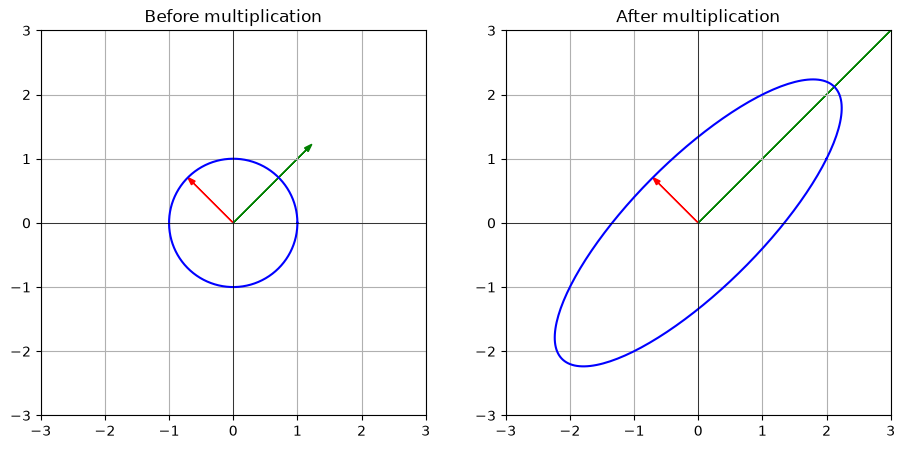

In [17]:
A = np.array([[2., 1.],[1., 2.]])   # symmetric
w, V = np.linalg.eigh(A)
v1 = V[:,0] * np.sqrt(w[0])
v2 = V[:,1] * np.sqrt(w[1])

theta = np.linspace(0, 2*np.pi, 200)
circle = np.stack([np.cos(theta), np.sin(theta)])

fig, axes = plt.subplots(1, 2, figsize=(11,5))

axes[0].plot(circle[0], circle[1], 'b-')
axes[0].arrow(0,0, v1[0], v1[1], color='red',  head_width=0.08, length_includes_head=True)
axes[0].arrow(0,0, v2[0], v2[1], color='green',head_width=0.08, length_includes_head=True)
axes[0].set_title("Before multiplication")

tr  = A @ circle
Av1 = A @ v1
Av2 = A @ v2
axes[1].plot(tr[0], tr[1], 'b-')
axes[1].arrow(0,0, Av1[0], Av1[1], color='red',  head_width=0.08, length_includes_head=True)
axes[1].arrow(0,0, Av2[0], Av2[1], color='green',head_width=0.08, length_includes_head=True)
axes[1].set_title("After multiplication")

for ax in axes:
    ax.set_aspect('equal')
    ax.set_xlim(-3,3); ax.set_ylim(-3,3)
    ax.axhline(0, color='black', lw=0.5)
    ax.axvline(0, color='black', lw=0.5)
plt.show()


## 14. Singular Value Decomposition

$A = U D V^T$. Works for any matrix shape.

In [18]:
A = np.array([[1., 2., 3.],[4., 5., 6.]])
U, S, Vt = np.linalg.svd(A, full_matrices=False)
print("U shape :", U.shape)
print("S       :", S)
print("Vt shape:", Vt.shape)

A_rec = U @ np.diag(S) @ Vt
print("Reconstruction matches?", np.allclose(A, A_rec))


U shape : (2, 2)
S       : [9.508 0.773]
Vt shape: (2, 3)
Reconstruction matches? True


## 15. Moore-Penrose Pseudoinverse

- Exactly one solution -> same as inverse
- No solution          -> minimum-error solution
- Many solutions       -> minimum-norm solution

In [19]:
A = np.array([[1., 2.],[3., 4.],[5., 6.]])   # 3x2, overdetermined
A_pinv = np.linalg.pinv(A)

print("A^+ A =\n", A_pinv @ A)
print("Close to I?", np.allclose(A_pinv @ A, np.eye(2)))

b = np.array([1., 2., 3.])
x = A_pinv @ b
print("Least-squares x =", x)
print("Residual ||Ax-b|| =", np.linalg.norm(A @ x - b))


A^+ A =
 [[ 1.  0.]
 [-0.  1.]]
Close to I? True
Least-squares x = [0.  0.5]
Residual ||Ax-b|| = 1.6616296724220897e-15


### 15.1 Pseudoinverse via SVD:  $A^+ = V D^+ U^T$

In [20]:
U, S, Vt = np.linalg.svd(A, full_matrices=False)
S_plus = np.where(S > 1e-10, 1.0/S, 0.0)
A_pinv_svd = Vt.T @ np.diag(S_plus) @ U.T
print("Matches np.linalg.pinv?", np.allclose(A_pinv_svd, np.linalg.pinv(A)))


Matches np.linalg.pinv? True


## 16. Trace

$\mathrm{Tr}(A) = \sum_i A_{i,i}$,  cyclic: $\mathrm{Tr}(ABC) = \mathrm{Tr}(CAB) = \mathrm{Tr}(BCA)$.

In [21]:
A = np.array([[1., 2.],[3., 4.]])
B = np.array([[5., 6.],[7., 8.]])
C = np.array([[9.,10.],[11.,12.]])

print("Tr(A)   =", np.trace(A))
print("Tr(ABC) =", np.trace(A@B@C))
print("Tr(CAB) =", np.trace(C@A@B))
print("Tr(BCA) =", np.trace(B@C@A))


Tr(A)   = 5.0
Tr(ABC) = 1443.0
Tr(CAB) = 1443.0
Tr(BCA) = 1443.0


## 17. A Tiny Neural Network Layer

$y = \sigma(Wx + b)$.

In [22]:
def sigmoid(z):
    return 1 / (1 + np.exp(-z))

W = np.array([[ 0.5, -0.2,  0.1],
              [-0.3,  0.8, -0.4]])
b = np.array([0.1, -0.2])
x = np.array([1.0, 0.5, -0.3])

z = W @ x + b
y = sigmoid(z)
print("z =", z)
print("y =", y)


z = [0.47 0.02]
y = [0.615 0.505]


## 18. Summary Cheat Sheet

| Concept | NumPy |
|---|---|
| Transpose | `A.T` |
| Matrix product | `A @ B` |
| Identity | `np.eye(n)` |
| Solve Ax=b | `np.linalg.solve(A,b)` |
| Inverse | `np.linalg.inv(A)` |
| Determinant | `np.linalg.det(A)` |
| Rank | `np.linalg.matrix_rank(A)` |
| Norm | `np.linalg.norm(x,p)` |
| Eigen | `np.linalg.eig(A)` / `np.linalg.eigh(A)` |
| SVD | `np.linalg.svd(A)` |
| Pseudoinverse | `np.linalg.pinv(A)` |
| Trace | `np.trace(A)` |
